# Playground - Part II

🎯 **Hedef**: ***Sinir Ağı hiperparametreleri*** hakkında daha iyi bir anlayış kazanmak

<hr>

👉  [Playground](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=3&seed=0.06711&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false&regularization_hide=false&regularizationRate_hide=false) tekrar açın. 

❗️ Algoritma stokastik olduğundan, sonuçların her çalıştırmada farklılık gösterebileceğini unutmayın. Bu nedenle, Sinir Ağlarınızın davranışını analiz etmek ve buna göre sonuçlarınızı çıkarmak için algoritmaları birden çok kez çalıştırmaktan çekinmeyin.

🕵🏻 Ders sırasında gördüğümüz farklı öğeleri inceleyelim:
- **Batch Size**
- **Regularization**
- **Learning Rate**

## (1) The batch size

❓ **İlk Soru** ❓ `circle dataset` (Sınıflandırma) seçin.

* Aşağıdakilerle bir model oluşturun:
* 3 nöronlu bir gizli katman,
* 0,03'e eşit bir a _learning rate_
* ve _tanh_ aktivasyon fonksiyonu

* Herhangi bir gürültü eklemeyin (=0).

* 30'luk bir batch size seçin

***Algoritmanın yakınsamasını inceleyin. Yavaş mı yoksa hızlı mı görünüyor?***

Batch size 30 ile modelin kayıp değerleri kademeli olarak azalmış ve 161 epoch sonunda training loss 0.059, test loss 0.068 seviyesine ulaşmıştır. Model sınıfları büyük ölçüde ayırmayı başarmıştır ancak yakınsama henüz tamamlanmamıştır. Bu nedenle öğrenme sürecinin görece yavaş ilerlediği gözlemlenmiştir.

❓ **Soru: 1'lik batch size' da ne oluyor?** ❓

Şimdi, bu sinir ağını aynı veri kümesinde çalıştırın, ancak...

* batch-size 1 olsun.
* En az 150 dönem çalıştırdığınızdan emin olun.

***Eğitim ve test kaybı hakkında ne fark ettiniz? Bu istikrarsızlığın nedeni nedir?***

Batch size 1 ile model 155 epoch sonunda training loss 0.003 ve test loss 0.026 değerlerine ulaşmıştır. Batch size 30'a göre kayıp değerleri daha hızlı azalmış ancak grafikte küçük dalgalanmalar oluşmuştur. Bunun nedeni, modelin ağırlıklarını her seferinde yalnızca bir veri örneğine göre güncellemesidir. Bu durum öğrenme sürecini daha değişken ve istikrarsız hale getirmektedir.

❓ **Soru/Gözlem** ❓

Şimdi, tren kaybı ve test kaybı değerlerini okuyarak _batch_size_'ın etkisini görebilirsiniz: yinelemeleri duraklatın ve `“Adım”` düğmesini (play/stop düğmesinin sağ tarafında) kullanarak adım adım (yineleme başına yineleme) çalıştırın.

Batch size 1 ile 216 epoch sonunda training loss 0.002, test loss 0.020 değerlerine ulaşılmıştır. Batch size 30 ile 214 epoch sonunda ise training loss 0.224, test loss 0.271 olarak gözlemlenmiştir. Batch size 1'de kayıp değerleri daha düşük olmasına rağmen küçük dalgalanmalar görülmektedir. Bunun nedeni, ağırlıkların her seferinde tek bir örneğe göre güncellenmesidir. Batch size 30'da güncellemeler daha istikrarlı olsa da aynı epoch sayısında model henüz yeterince yakınsamamıştır.

## 2. Regularization (Düzenleme)

❓ **Genelleme eksikliği hakkında soru** ❓ 

**Genelleme eksikliğini** bir kez daha gözlemlemek için:
* `“eXclusive OR”(XOR)` veri setini seçin, 
* gürültü seviyesi 50 olsun,
* 8 nöronlu iki gizli katman kullanın. 

***Modelinizi uyumlaştırmaya çalışın... Ne bekliyorsunuz?***

> <b>Noise seviyesi 50 olan XOR veri kümesinde, iki gizli katmanda 8'er nöron kullanılarak model eğitilmiştir. 1010 epoch sonunda training loss 0.207, test loss 0.266 olarak gözlemlenmiştir. Model XOR örüntüsünü büyük ölçüde öğrenmiş ancak gürültülü veriler nedeniyle tüm noktaları doğru sınıflandıramamıştır. Eğitim kaybının test kaybından düşük olması genelleme farkına işaret etmektedir. Model eğitilmeye devam edilirse gürültüyü de öğrenerek overfitting oluşması beklenebilir.</b>

❗️ Daha küçük bir parti boyutu ile, modeliniz daha hızlı aşırı uyumlanacaktır... ❗️

👉 Bununla birlikte, bir sonraki soru için ***`batch size = 1`*** değerini koruyalım ve `düzenleme` (`regularization`) stratejisini kullanarak aşırı uyumlanmayı nasıl önleyebileceğimizi anlamaya çalışalım.

❓ **Düzenlemeyle (regularization) ilgili soru** ❓

Ağımızı ***avoid overfitting*** için ***düzenleyebilir miyiz***?

* Toplu işleme boyutunu 1 olarak tutun,
* Bir `L2-regularization` ekleyin,
* Karar sınırını düzeltene kadar bu L2 düzenlemesinin gücünü artırın!
Test kaybının artık dönemlerle birlikte artmadığını fark edin.

L2 regularization değeri artırıldığında modelin daha dengeli öğrenmeye başladığı gözlemlenmiştir. L2 değeri 0 iken training loss 0.177, test loss 0.332 iken, L2 değeri 0.03 olduğunda training loss 0.250, test loss 0.251 olmuştur. Düzenlileştirme arttıkça eğitim hatası yükselmesine rağmen test hatası azalmış ve iki değer arasındaki fark küçülmüştür. Bu sonuç, L2 regularization yönteminin aşırı öğrenmeyi azaltarak modelin genelleme performansını iyileştirebildiğini göstermektedir.

❓ **Spiral veri setiyle ilgili sorular** ❓

<u>Yapılandırma</u>:

* `spiral` veri setini seç,
* Regularization’ı kaldır,
* `training/test` veri oranını %80 eğitim olacak şekilde artır.

<u>Sinir Ağı</u>: 3 gizli katman:
* 1. katmanda 8 nöron,
* 2. katmanda 7 nöron,
* 3. katmanda 6 nöron.

<u>Deney</u>:

* Algoritmayı batch size = 30 ile çalıştır,
* En az 1500 epoch çalıştırdığından emin ol,
* Sonra aynı deneyi batch size = 1 ile yapıp karşılaştır.

Train loss ve test loss değerlerinde adım adım ne olduğuna bakabilirsin.

Spiral veri setinde batch size 30 ile 1510 epoch sonunda training loss 0.350, test loss 0.497 olarak gözlemlenmiştir. Batch size 1 ile 1508 epoch sonunda training loss 0.319'a düşerken test loss 0.523'e yükselmiştir. Batch size 1 kullanıldığında kayıp grafiğinde daha fazla dalgalanma ve ani değişimler görülmüştür. Bunun nedeni, ağırlıkların her seferinde tek bir örneğe göre güncellenmesidir. Batch size 30 ise daha istikrarlı bir öğrenme süreci göstermiş ve bu deneyde daha düşük test kaybına ulaşmıştır. Her iki model de spiral yapısını tam olarak öğrenememiştir.

## (3) The learning rate (Öğrenme oranı)

<u>`circle veri setine`</u> geri dön:

* Gürültü (noise) olmadan,
* Eğitim / test veri oranı %50 olacak şekilde,
* Batch size = 20 kullan.

<u>Sinir ağı</u> ayarları:
* 5 nöronlu tek bir katman,
* Regularization yok,
* `tanh` aktivasyon fonksiyonu.

❓ **Learning rate ile ilgili soru** ❓

Her bir learning rate değeri için (0.0001’den 10’a kadar):
* Algoritmayı 1000 epoch boyunca çalıştır,
* Test loss değerlerini aşağıdaki listeye kaydet,
* Ardından test loss değerlerini learning rate’e göre çiz (plot).

❗️ <u>Uyarı</u> ❗️  
Learning rate’i her değiştirdiğinde sinir ağını mutlaka **yeniden başlat**  
(_play/pause tuşunun solundaki circular arrow_).

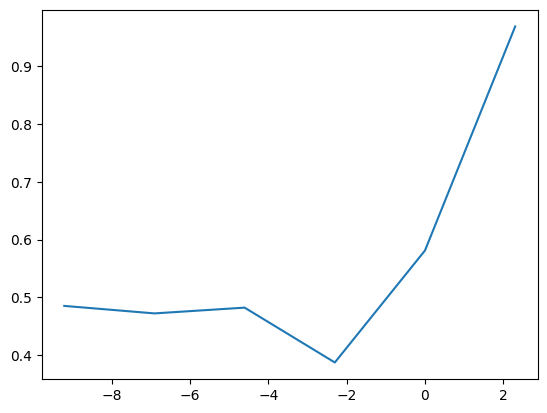

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

import numpy as np

learning_rates = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]
test_loss = [0.485, 0.472, 0.482, 0.387, 0.581, 0.969]


plt.plot(np.log(learning_rates), test_loss)

❗️ <u>Uyarı</u> ❗️  
Hem **çok düşük** hem de **çok yüksek** learning rate değerleri yüksek test loss’a yol açar… fakat **farklı nedenlerle**!

* **Düşük learning rate**:
  - Sinir ağının, orta seviyedeki bir learning rate’e benzer şekilde yakınsamasını sağlar
  - Ancak **çok daha yavaş** olur → yani **daha fazla epoch** gerekir

* **Yüksek learning rate**:
  - Algoritmanın tamamen **dağılmasına (diverge)** neden olur
  - Örneğin learning rate \( \alpha = 10 \) ve 400 epoch dene:
    - Loss değerinin sürekli değiştiğini görürsün
    - Bu durum, algoritmanın **farklı yerel minimumlara** yakınsadığını gösterir

🏁 Tebrikler!

💾 Not defterinizi `git add/commit/push` yapmayı unutmayın...